**Analisi computazionale di architetture JEPA-like su acceleratori per sistemi embedded**

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torchvision.transforms as T
from skimage import data
from sklearn.decomposition import PCA

torch.manual_seed(42)

# ============================================================
# 1. CARICAMENTO DEL MODELLO
# ============================================================
print("Caricamento modello DINOv2 ViT-small...")
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
model.eval()

GPU_AVAILABLE = torch.cuda.is_available()
if not GPU_AVAILABLE:
    print("ATTENZIONE: GPU non disponibile")
final_device = 'cuda' if GPU_AVAILABLE else 'cpu'


# ============================================================
# 1B. SETUP SPERIMENTALE
# ============================================================
import platform

print("=== EXPERIMENTAL SETUP ===")
print(f"PyTorch: {torch.__version__} | CUDA: {torch.version.cuda}")

# Ricavo il nome della CPU
cpu_name = platform.processor()
print(f"CPU: {cpu_name} ({torch.get_num_threads()} thread PyTorch)")

if GPU_AVAILABLE:
  print(
      f"GPU: {torch.cuda.get_device_name(0)} "
      f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)"
  )

print(f"Datatype pesi: {next(model.parameters()).dtype}")

Caricamento modello DINOv2 ViT-small...
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 200MB/s]


=== EXPERIMENTAL SETUP ===
PyTorch: 2.11.0+cu130 | CUDA: 13.0
CPU: x86_64 (1 thread PyTorch)
GPU: Tesla T4 (15.6 GB)
Datatype pesi: torch.float32


Caricamento immagini di test...


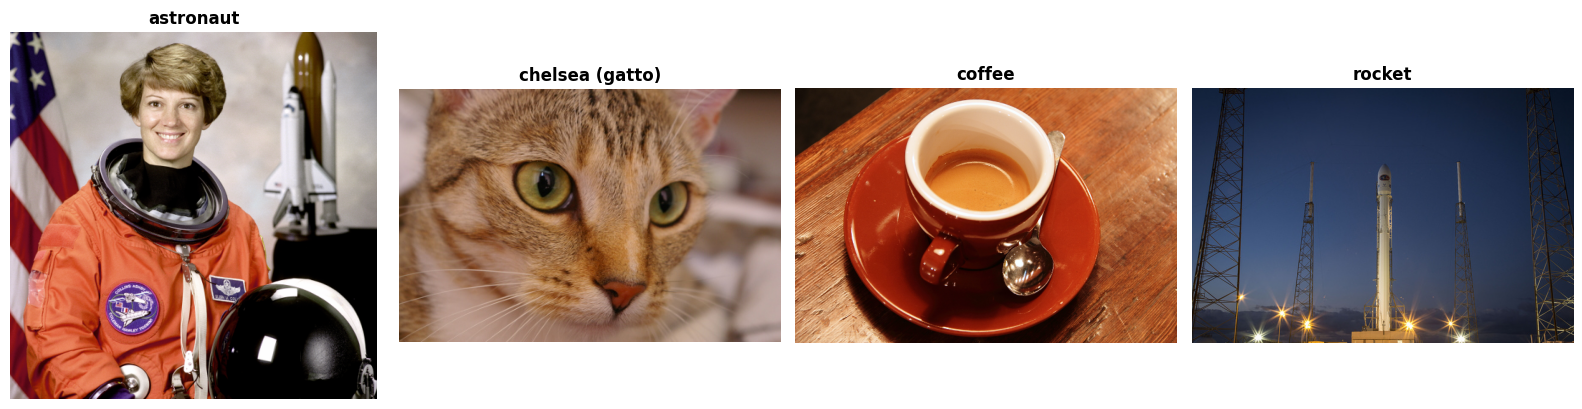

Sequenza reale: 257 token, embedding dim: 384


In [2]:
# ============================================================
# 2. CARICAMENTO E PREPROCESSING DI IMMAGINI DI TEST
# ============================================================
print("Caricamento immagini di test...")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

preprocess = T.Compose([
    T.ToPILImage(),
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_images_raw = {
    'astronaut': data.astronaut(),
    'chelsea (gatto)': data.chelsea(),
    'coffee': data.coffee(),
    'rocket': data.rocket(),
}

test_tensors, test_names = [], []
for name, img_np in test_images_raw.items():
    test_tensors.append(preprocess(img_np))
    test_names.append(name)

# Creo una griglia di subplot (1 riga, N colonne)
fig, axes = plt.subplots(1, len(test_names), figsize=(4 * len(test_names), 4))

for i, name in enumerate(test_names):
    axes[i].imshow(test_images_raw[name])  # Mostra l'immagine originale
    axes[i].set_title(name, fontsize=12, fontweight='bold')
    axes[i].axis('off')  # Rimuove gli assi cartesiani numerici

plt.tight_layout()
plt.show()

test_batch_raw = torch.stack(test_tensors)  # 4 tensori in un tensore di dimensione (4, 3, 224, 224) - Dimensione del Batch (il numero di immagini), C, H, W

# Ricavo la lunghezza reale della sequenza di token direttamente da un'immagine
with torch.no_grad():
    patch_tokens_probe = model.patch_embed(test_batch_raw)      # (4, 256, 384)
seq_len = patch_tokens_probe.shape[1] + 1  # +1 per il token CLS (Class Token)
embed_dim = patch_tokens_probe.shape[2]                         # (4, 257, 384)
print(f"Sequenza reale: {seq_len} token, embedding dim: {embed_dim}")

# Per il benchmark di latenza serve un batch di dimensione fissa (8):
# replico le immagini reali fino a raggiungere batch_size.
batch_size = 8
repeats = (batch_size + test_batch_raw.shape[0] - 1) // test_batch_raw.shape[0]
test_input = test_batch_raw.repeat(repeats, 1, 1, 1)[:batch_size]  # test_input è ora un tensore di dimensioni (8, 3, 224, 224)

# Batch sintetico usato SOLO per il profiling isolato di attention/MLP
# a livello di singolo blocco (qui serve solo la forma corretta del tensore
# intermedio, non un'immagine vera).
dummy_b_cpu = torch.randn(8, seq_len, embed_dim)
dummy_b_gpu = dummy_b_cpu.to('cuda') if GPU_AVAILABLE else None

In [3]:
# ============================================================
# 3. MISURAZIONE INFERENZA, LATENZA E DEVIAZIONE STANDARD
# ============================================================
def measure_execution_time(model, x, device, runs=30, warmup=10):
    model = model.to(device)
    x = x.to(device)               # x è il tensore
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(x)
    if device == 'cuda':
        torch.cuda.synchronize()   #La CPU aspetta finché la GPU non ha finito

    times = []
    with torch.no_grad():
        for _ in range(runs):
            start = time.perf_counter()
            _ = model(x)           # E' l'inferenza
            if device == 'cuda':
                torch.cuda.synchronize()
            times.append((time.perf_counter() - start) * 1000)
    return float(np.mean(times)), float(np.std(times))

print("Misurazione latenza totale rete su immagini reali...")
time_cpu, std_cpu = measure_execution_time(model, test_input, device='cpu', runs=10)
if GPU_AVAILABLE:
    time_gpu, std_gpu = measure_execution_time(model, test_input, device='cuda', runs=50)
else:
    time_gpu, std_gpu = None, None

throughput_cpu = batch_size / (time_cpu / 1000)       # num di immagini elaborate al secondo
throughput_gpu = batch_size / (time_gpu / 1000) if GPU_AVAILABLE else None

Misurazione latenza totale rete su immagini reali...


In [4]:
# ============================================================
# 4. MISURAZIONE SPECIFICA: ATTENTION vs MLP vs BLOCCO INTERO
#    Ripetuta N_REPEATS volte in esecuzioni indipendenti per
#    mediare via il rumore di sistema della CPU condivisa di Colab.
#    La normalizzazione (norm1/norm2) viene calcolata UNA VOLTA,
#    fuori dal timer, in modo da isolare il costo puro di
#    attention e MLP (senza il contributo della LayerNorm).
# ============================================================
print("Attention vs MLP vs Blocco intero (ripetizioni multiple)...")

WARMUP_ITERS = 5
RUNS_CPU = 20
RUNS_GPU = 50
N_REPEATS = 5  # esecuzioni indipendenti da mediare

n_blocks = len(model.blocks)
block_names = [f"Block_{idx}" for idx in range(n_blocks)]

# Shape: (N_REPEATS, n_blocks)
attn_cpu_runs = np.zeros((N_REPEATS, n_blocks))
mlp_cpu_runs = np.zeros((N_REPEATS, n_blocks))
block_cpu_runs = np.zeros((N_REPEATS, n_blocks))
attn_gpu_runs = np.zeros((N_REPEATS, n_blocks))
mlp_gpu_runs = np.zeros((N_REPEATS, n_blocks))
block_gpu_runs = np.zeros((N_REPEATS, n_blocks))

for rep in range(N_REPEATS):
    print(f"  Ripetizione {rep + 1}/{N_REPEATS}...")
    for idx, block in enumerate(model.blocks):
        b_cpu = block.to('cpu')
        with torch.no_grad():
            for _ in range(WARMUP_ITERS):
                _ = b_cpu.attn(b_cpu.norm1(dummy_b_cpu))
                _ = b_cpu.mlp(b_cpu.norm2(dummy_b_cpu))
                _ = b_cpu(dummy_b_cpu)

        # Calcolo della normalizzazione
        with torch.no_grad():
            normed1_cpu = b_cpu.norm1(dummy_b_cpu)
            normed2_cpu = b_cpu.norm2(dummy_b_cpu)

        # Attention
        start = time.perf_counter()
        with torch.no_grad():
            for _ in range(RUNS_CPU):
                _ = b_cpu.attn(normed1_cpu)
        attn_cpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_CPU) * 1000

        # MLP
        start = time.perf_counter()
        with torch.no_grad():
            for _ in range(RUNS_CPU):
                _ = b_cpu.mlp(normed2_cpu)
        mlp_cpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_CPU) * 1000

        # Blocco intero (norm1 + attn + residuo + norm2 + mlp + residuo)
        start = time.perf_counter()
        with torch.no_grad():
            for _ in range(RUNS_CPU):
                _ = b_cpu(dummy_b_cpu)
        block_cpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_CPU) * 1000

        if GPU_AVAILABLE:
            b_gpu = block.to('cuda')
            with torch.no_grad():
                for _ in range(WARMUP_ITERS):
                    _ = b_gpu.attn(b_gpu.norm1(dummy_b_gpu))
                    _ = b_gpu.mlp(b_gpu.norm2(dummy_b_gpu))
                    _ = b_gpu(dummy_b_gpu)
            torch.cuda.synchronize()

            # Normalizzazione GPU
            with torch.no_grad():
                normed1_gpu = b_gpu.norm1(dummy_b_gpu)
                normed2_gpu = b_gpu.norm2(dummy_b_gpu)
            torch.cuda.synchronize()

            # Attention
            start = time.perf_counter()
            with torch.no_grad():
                for _ in range(RUNS_GPU):
                    _ = b_gpu.attn(normed1_gpu)
                    torch.cuda.synchronize()
            attn_gpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_GPU) * 1000

            # MLP
            start = time.perf_counter()
            with torch.no_grad():
                for _ in range(RUNS_GPU):
                    _ = b_gpu.mlp(normed2_gpu)
                    torch.cuda.synchronize()
            mlp_gpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_GPU) * 1000

            # Blocco intero
            start = time.perf_counter()
            with torch.no_grad():
                for _ in range(RUNS_GPU):
                    _ = b_gpu(dummy_b_gpu)
                    torch.cuda.synchronize()
            block_gpu_runs[rep, idx] = ((time.perf_counter() - start) / RUNS_GPU) * 1000

model = model.to(final_device)

# Aggregazione: media e deviazione standard tra le N_REPEATS ripetizioni
attn_times_cpu = attn_cpu_runs.mean(axis=0)
mlp_times_cpu = mlp_cpu_runs.mean(axis=0)
block_cpu_mean = block_cpu_runs.mean(axis=0)
block_cpu_std = block_cpu_runs.std(axis=0)

if GPU_AVAILABLE:
    attn_times_gpu = attn_gpu_runs.mean(axis=0)
    mlp_times_gpu = mlp_gpu_runs.mean(axis=0)
    block_gpu_mean = block_gpu_runs.mean(axis=0)
    block_gpu_std = block_gpu_runs.std(axis=0)

Attention vs MLP vs Blocco intero (ripetizioni multiple)...
  Ripetizione 1/5...
  Ripetizione 2/5...
  Ripetizione 3/5...
  Ripetizione 4/5...
  Ripetizione 5/5...


In [5]:
# ============================================================
# 5. CALCOLO PARAMETRI E FLOPs PER BLOCCO
# ============================================================
print("\nCalcolo analitico di Parametri e FLOPs per ciascun blocco...")

params_per_block = []
flops_per_block = []

for block in model.blocks:
    # 1. Numero di Pesi (Parametri) in milioni
    p_count = sum(p.numel() for p in block.parameters())
    params_per_block.append(p_count / 1e6)

    # 2. Stima analitica dei FLOPs per un singolo blocco ViT:
    # Attention: Proiezioni QKV + Matrix Multiply Q*K^T & Attn*V + Proiezione Output
    # MLP: Linear 1 (384 -> 1536) + Linear 2 (1536 -> 384)
    B, N, D = batch_size, seq_len, embed_dim
    flops_attn = (2 * B * N * (3 * D) * D) + (4 * B * (N**2) * D) + (2 * B * N * D * D)
    flops_mlp = (2 * B * N * D * (4 * D)) + (2 * B * N * (4 * D) * D)
    total_flops = (flops_attn + flops_mlp) / 1e9  # Convertito in GFLOPs
    flops_per_block.append(total_flops)


Calcolo analitico di Parametri e FLOPs per ciascun blocco...


In [6]:
# ============================================================
# 6. DATAFRAME
# ============================================================
df_res = pd.DataFrame({
    'Block': block_names,
    'Params_M': params_per_block,
    'GFLOPs': flops_per_block,
    'CPU_Time_ms': block_cpu_mean,
    'CPU_Time_std': block_cpu_std,
    'GPU_Time_ms': block_gpu_mean if GPU_AVAILABLE else np.nan,
    'GPU_Time_std': block_gpu_std if GPU_AVAILABLE else np.nan,
})
if GPU_AVAILABLE:
    df_res['Speedup'] = df_res['CPU_Time_ms'] / df_res['GPU_Time_ms']

print(f"\nCoefficiente di variazione medio CPU tra ripetizioni: "
      f"{(block_cpu_std / block_cpu_mean).mean() * 100:.1f}% "
      f"(indica quanto rumore di sistema affligge le misure per-blocco su CPU)")


Coefficiente di variazione medio CPU tra ripetizioni: 1.6% (indica quanto rumore di sistema affligge le misure per-blocco su CPU)


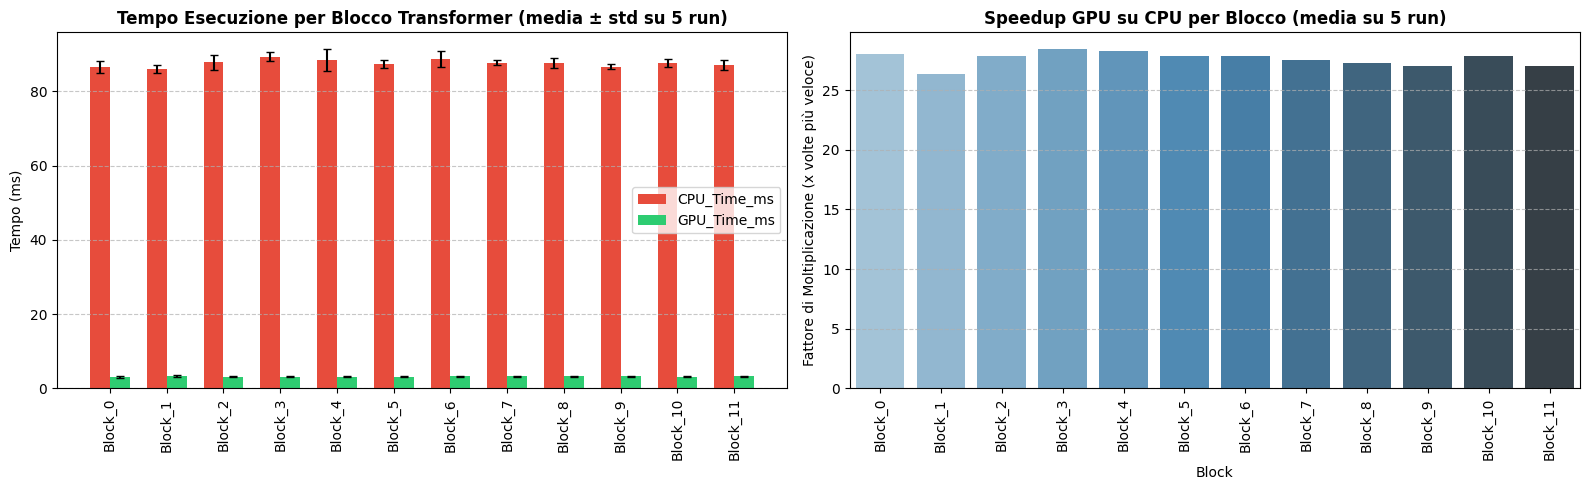

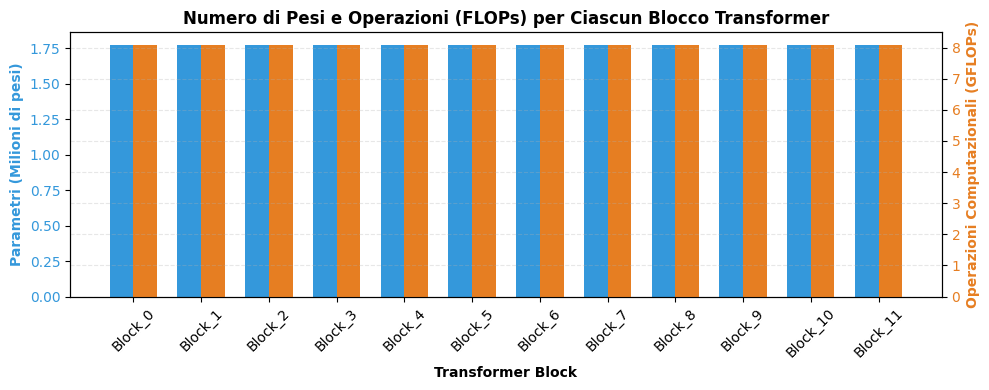

In [7]:
# ============================================================
# 7. GENERAZIONE GRAFICI
# ============================================================

# GRAFICO 1: Tempi di esecuzione e Speedup per Blocco
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x_pos = np.arange(n_blocks)
width = 0.35
axes[0].bar(x_pos - width/2, df_res['CPU_Time_ms'], width, yerr=df_res['CPU_Time_std'],
            label='CPU_Time_ms', color='#e74c3c', capsize=3)
if GPU_AVAILABLE:
    axes[0].bar(x_pos + width/2, df_res['GPU_Time_ms'], width, yerr=df_res['GPU_Time_std'],
                label='GPU_Time_ms', color='#2ecc71', capsize=3)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_res['Block'], rotation=90)
axes[0].set_title(f'Tempo Esecuzione per Blocco Transformer (media ± std su {N_REPEATS} run)', fontweight='bold')
axes[0].set_ylabel('Tempo (ms)')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

if GPU_AVAILABLE:
    sns.barplot(data=df_res, x='Block', y='Speedup', ax=axes[1], hue='Block', palette='Blues_d', legend=False)
    axes[1].set_title(f'Speedup GPU su CPU per Blocco (media su {N_REPEATS} run)', fontweight='bold')
    axes[1].set_ylabel('Fattore di Moltiplicazione (x volte più veloce)')
    axes[1].tick_params(axis='x', rotation=90)
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('block_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


# GRAFICO 2: Numero di Pesi e Operazioni (FLOPs) per Ciascun Blocco
fig, ax1 = plt.subplots(figsize=(10, 4))

color = '#3498db'
ax1.set_xlabel('Transformer Block', fontweight='bold')
ax1.set_ylabel('Parametri (Milioni di pesi)', color=color, fontweight='bold')
bars1 = ax1.bar(x_pos - width/2, df_res['Params_M'], width, color=color, label='Pesi (M)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_res['Block'], rotation=45)

ax2 = ax1.twinx()  # Secondo asse Y a destra
color = '#e67e22'
ax2.set_ylabel('Operazioni Computazionali (GFLOPs)', color=color, fontweight='bold')
bars2 = ax2.bar(x_pos + width/2, df_res['GFLOPs'], width, color=color, label='FLOPs (GFLOPs)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Numero di Pesi e Operazioni (FLOPs) per Ciascun Blocco Transformer', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('params_flops_per_block.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# ============================================================
# 8. OUTPUT RISULTATI FINALI
# ============================================================
print(f"\n=================== RISULTATI COMPLESSIVI (immagini reali) ===================")
print(f"Latenza totale rete su CPU: {time_cpu:.2f} ± {std_cpu:.2f} ms | Throughput: {throughput_cpu:.1f} FPS (img/s)")
if GPU_AVAILABLE:
    print(f"Latenza totale rete su GPU: {time_gpu:.2f} ± {std_gpu:.2f} ms | Throughput: {throughput_gpu:.1f} FPS (img/s)")
    print(f"Speedup reale dell'acceleratore GPU: {time_cpu / time_gpu:.2f}x")

print(f"\n--- ANALISI COMPONENTI ARCHITETTURALI ---")
print(f"Tempo totale Self-Attention  -> CPU: {sum(attn_times_cpu):.2f} ms", end="")
if GPU_AVAILABLE:
    print(f" | GPU: {sum(attn_times_gpu):.2f} ms (Speedup: {sum(attn_times_cpu)/sum(attn_times_gpu):.2f}x)")
else:
    print()
print(f"Tempo totale MLP (MatMul)    -> CPU: {sum(mlp_times_cpu):.2f} ms", end="")
if GPU_AVAILABLE:
    print(f" | GPU: {sum(mlp_times_gpu):.2f} ms (Speedup: {sum(mlp_times_cpu)/sum(mlp_times_gpu):.2f}x)")
else:
    print()
print(f"=================================================================================")


=================== RISULTATI COMPLESSIVI (immagini reali) ===================
Latenza totale rete su CPU: 1207.11 ± 236.17 ms | Throughput: 6.6 FPS (img/s)
Latenza totale rete su GPU: 34.30 ± 0.44 ms | Throughput: 233.3 FPS (img/s)
Speedup reale dell'acceleratore GPU: 35.20x

--- ANALISI COMPONENTI ARCHITETTURALI ---
Tempo totale Self-Attention  -> CPU: 389.26 ms | GPU: 22.42 ms (Speedup: 17.36x)
Tempo totale MLP (MatMul)    -> CPU: 616.88 ms | GPU: 22.70 ms (Speedup: 27.18x)


In [9]:
# ============================================================
# 9. FP32 vs BFLOAT16 SU GPU (latenza, FPS, picco memoria)
# ============================================================
import copy

if GPU_AVAILABLE:
    print("\n=== Test comparativo FP32 vs BFLOAT16 su GPU ===")
    print(f"bf16 supportato: {torch.cuda.is_bf16_supported()}")
    x_fp32 = test_input.to("cuda")

    # --- FP32 ---
    model_gpu = model.to("cuda")
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    time_fp32, std_fp32 = measure_execution_time(model_gpu, x_fp32, "cuda", runs=50)
    mem_fp32 = torch.cuda.max_memory_allocated() / 1e6   # MB
    fps_fp32 = batch_size / (time_fp32 / 1000)

    model.to("cpu")              # libero la GPU prima della misura bf16
    torch.cuda.empty_cache()

    # --- BF16: cast di modello e input, su una copia ---
    model_bf16 = copy.deepcopy(model).to(torch.bfloat16).to("cuda")
    x_bf16 = x_fp32.to(torch.bfloat16)
    torch.cuda.reset_peak_memory_stats()
    time_bf16, std_bf16 = measure_execution_time(model_bf16, x_bf16, "cuda", runs=50)
    mem_bf16 = torch.cuda.max_memory_allocated() / 1e6
    fps_bf16 = batch_size / (time_bf16 / 1000)
    del model_bf16
    torch.cuda.empty_cache()

    print(f"FP32 -> {time_fp32:.2f} ± {std_fp32:.2f} ms | {fps_fp32:.1f} FPS | picco {mem_fp32:.0f} MB")
    print(f"BF16 -> {time_bf16:.2f} ± {std_bf16:.2f} ms | {fps_bf16:.1f} FPS | picco {mem_bf16:.0f} MB")
    print(f"Speedup BF16 vs FP32: {time_fp32 / time_bf16:.2f}x | Memoria: {(1 - mem_bf16 / mem_fp32) * 100:.0f}% in meno")



=== Test comparativo FP32 vs BFLOAT16 su GPU ===
bf16 supportato: True
FP32 -> 40.91 ± 0.82 ms | 195.5 FPS | picco 159 MB
BF16 -> 52.85 ± 0.74 ms | 151.4 FPS | picco 126 MB
Speedup BF16 vs FP32: 0.77x | Memoria: 21% in meno
